In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

df = pd.read_csv(r"C:\Users\Administrator\Documents\kenya_market_prices\data\food-prices-kenya.csv")

df.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [3]:
df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [5]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [6]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1450,2018-08-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,7650.00,75.97
1662,2008-08-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,5239.47,77.74
821,2012-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,61.35,0.71
1464,2019-10-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,7785.00,75.11
1054,2017-09-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,70.00,0.68
1639,2006-09-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3043.75,41.58
205,2013-04-15,Eastern,Kitui,Kitui,Beans,Retail,KG,73.00,0.87
657,2012-05-15,Eastern,Kitui,Kitui,Maize,Retail,KG,41.00,0.49
2163,2017-12-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2410.00,23.38
1212,2012-06-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,52.94,0.62


In [7]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(20, random_state=42)


859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
1364   2011-05-15
1102   2016-10-15
1601   2017-05-15
1179   2009-06-15
2030   2006-10-15
677    2014-01-15
1117   2018-01-15
1607   2017-11-15
1820   2008-02-15
2104   2013-01-15
Name: date, dtype: datetime64[us]

In [8]:
#add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [9]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1198,2011-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,38.0,0.47,2011,1
1776,2018-04-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,5725.0,56.95,2018,4
196,2012-07-15,Eastern,Kitui,Kitui,Beans,Retail,KG,82.0,0.98,2012,7
1882,2013-04-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,5938.0,70.94,2013,4
2710,2017-05-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,4000.0,38.82,2017,5


In [10]:
#fill the missing county and region for the market that has none
#df["county"].isna().sum()
df["region"].isna().sum()





np.int64(59)

In [11]:
#How many rows, markets and commodities does the file have, 
df.shape
#2742 -rows, 11- columns

(2742, 11)

In [12]:
#and what are the first and last dates?

# Highest and lowest date in the dataset
highest_date = df['date'].max()
lowest_date = df['date'].min()

print(highest_date)
print(lowest_date)

#last date2019-12-15
#first date2006-01-15

2019-12-15 00:00:00
2006-01-15 00:00:00


In [13]:
#which market has no county and how many rows does that affect?
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [16]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""

' Compare like with like\nSplit the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. \nAdd a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.\n- Which units appear for wholesale maize and for retail maize?\n- On average, how does the retail price per KG of maize compare with the wholesale price per KG?\n'

In [17]:
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])
df.sample(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
162,2009-09-15,Eastern,Kitui,Kitui,Beans,Retail,KG,60.0,0.79,2009,9,60.000000
22,2016-12-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,94.0,0.92,2016,12,94.000000
133,2007-04-15,Eastern,Kitui,Kitui,Beans,Retail,KG,30.0,0.44,2007,4,30.000000
2577,2011-02-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,2087.0,25.65,2011,2,23.188889
2242,2010-08-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,1560.0,19.45,2010,8,17.333333
227,2015-02-15,Eastern,Kitui,Kitui,Beans,Retail,KG,71.0,0.78,2015,2,71.000000
2528,2007-01-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,1337.5,19.22,2007,1,14.861111
2178,2019-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1856.0,18.53,2019,3,20.622222
1437,2017-07-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,10350.0,99.63,2017,7,115.000000
2121,2014-06-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,3100.0,35.28,2014,6,34.444444


In [18]:
#this code splits the dataset into a wholesale-only dataframe
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [19]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [20]:
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()


np.float64(28.54230389890584)

In [21]:
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [22]:
#Calculate the average wholesale maize price per bag for each year and the year-on-year change. Plot the yearly average as a line chart with the price in KES on the y-axis.

df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.244444
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.488889
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.913556
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.188889
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.058444
2026,2006-06-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1549.00,21.06,2006,6,17.211111
2027,2006-07-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1550.00,21.08,2006,7,17.222222
2028,2006-08-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1529.50,21.07,2006,8,16.994444
2029,2006-09-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1124.38,15.36,2006,9,12.493111
2030,2006-10-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1053.00,14.60,2006,10,11.700000


In [23]:

#Calculate the average wholesale maize price per bag for each year and the year-on-year change.
yearly_avg = (
    df_maize.groupby("year", as_index=False)["price_kes"]
    .mean()
    .rename(columns={"price_kes": "avg_price_kes"})
)[["year", "avg_price_kes"]]
yearly_avg

,year,avg_price_kes
0,2006,1395.036875
1,2007,1207.450625
2,2008,1906.319149
3,2009,2513.271875
4,2010,1773.951458
5,2011,3020.218750
6,2012,3173.782609
7,2013,2962.458333
8,2014,2993.717083
9,2015,2690.149833


In [24]:

#Which year had the highest average wholesale maize price? 2011
#Which year saw the biggest rise, and which saw the biggest fall, compared with the year before? biggest rise: 2011, biggest fall:2012

yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.036875,NaN
1,2007,1207.450625,-187.586250
2,2008,1906.319149,698.868524
3,2009,2513.271875,606.952726
4,2010,1773.951458,-739.320417
5,2011,3020.218750,1246.267292
6,2012,3173.782609,153.563859
7,2013,2962.458333,-211.324275
8,2014,2993.717083,31.258750
9,2015,2690.149833,-303.567250


In [25]:
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax()]

year              2017.00000
avg_price_kes     3743.68050
yoy_change_kes     981.02675
Name: 11, dtype: float64

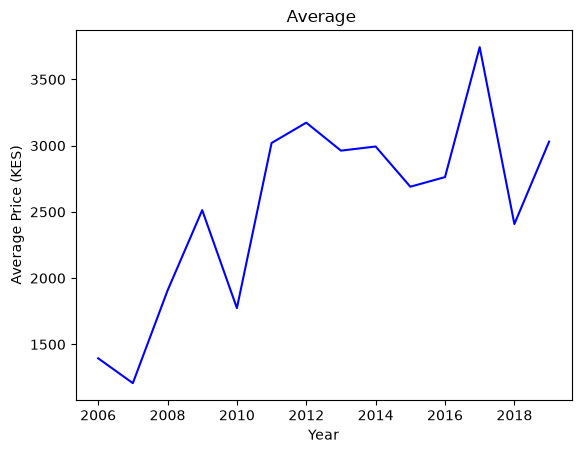

In [26]:
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="blue")
plt.xlabel("Year")
plt.ylabel("Average Price (KES)")
plt.title("Average ")
plt.show()

In [27]:
print(
    f"Highest wholesale price year: "
    f"{yearly_avg.loc[yearly_avg['avg_price_kes'].idxmax(), 'year']}"
)

Highest wholesale price year: 2017


In [28]:
print(
    f"Lowest wholesale price year: "
    f"{yearly_avg.loc[yearly_avg['avg_price_kes'].idxmin(), 'year']}"
)

Lowest wholesale price year: 2007


In [29]:
yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmax()]
#yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmin()]


year              2011.000000
avg_price_kes     3020.218750
yoy_change_kes    1246.267292
Name: 5, dtype: float64

In [ ]:
#Average wholesale maize prices by month to find the seasonal pattern.
df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(10)

yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg

,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [ ]:
 
# Then compare each market's January and June price, year by year, to see how often storing maize for five months paid off.
monthly_avg = df_maize.groupby("month")["price_kes"].mean().reset_index().round(2)
monthly_avg
monthly_avg.columns = ["month", "avg_months_kes"]
monthly_avg.columns




np.int32(6)

In [ ]:
#in which month is wholesale maize cheapest on average, and in which is it dearest?
cheapest_avg = monthly_avg.loc[monthly_avg["avg_months_kes"].idxmin(), "month"] #january (1)
cheapest_avg

dearest_avg = monthly_avg.loc[monthly_avg["avg_months_kes"].idxmax(), "month"] #june(6)
dearest_avg

In [ ]:
Then #compare each market's January and June price, year by year, to see how often storing maize for five months paid off.
wholesale_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy()

# Compare January and June prices for each market-year
market_year_prices = (wholesale_maize[wholesale_maize["month"].isin([1, 6])]
    .groupby(["market", "year", "month"])["price_kes"]
    .mean()
    .unstack("month")
    .rename(columns={1: "January", 6: "June"})
    .dropna(subset=["January", "June"])
)

market_year_prices["gain"] = (market_year_prices["June"] - market_year_prices["January"])
market_year_prices


month         January     June     gain
market  year                           
Eldoret 2006  1192.00  1549.00   357.00
        2007   947.50  1204.71   257.21
        2008  1200.00  1776.00   576.00
        2009  1743.00  2776.00  1033.00
        2010  2142.00  1556.00  -586.00
        2011  1390.00  3800.00  2410.00
        2012  2800.00  2960.00   160.00
        2013  2642.00  2710.00    68.00
        2014  2794.00  3100.00   306.00
        2015  2000.00  2550.00   550.00
        2016  2210.00  2600.00   390.00
        2017  2780.00  4320.00  1540.00
        2018  2485.00  2030.00  -455.00
        2019  1684.00  3200.00  1516.00
Kisumu  2006  1320.00  1714.00   394.00
        2007  1400.00  1272.22  -127.78
        2009  2800.00  2633.00  -167.00
        2010  2395.00  1724.00  -671.00
        2011  2031.00  4620.00  2589.00
        2012  3600.00  4280.00   680.00
        2013  3200.00  3600.00   400.00
        2014  3600.00  3929.00   329.00
        2015  3200.00  3100.00  -100.00
        2016  3200.00  3200.00     0.00
        2017  3600.00  4880.00  1280.00
        2018  3600.00  3200.00  -400.00
        2019  2600.00  4240.00  1640.00
Mombasa 2006  1480.00  1814.75   334.75
        2007  1061.90  1200.00   138.10
        2008  1431.58  1909.29   477.71
        2009  2098.75  2435.00   336.25
        2010  2306.67  1526.00  -780.67
        2011  1710.00  3800.00  2090.00
        2012  3020.00  3375.00   355.00
        2013  1545.00  2835.00  1290.00
        2014  3000.00  3288.00   288.00
        2015  2372.00  3013.00   641.00
        2016  2700.00  2670.00   -30.00
        2017  3135.00  4806.50  1671.50
        2018  2808.00  2690.00  -118.00
        2019  2305.00  3317.50  1012.50
Nairobi 2006  1399.00  1550.91   151.91
        2007  1337.50  1204.44  -133.06
        2008  1347.00  2165.00   818.00
        2009  2221.00  2854.00   633.00
        2010  2525.00  1948.00  -577.00
        2011  2000.00  3800.00  1800.00
        2012  3000.00  3650.00   650.00
        2013  3000.00  3020.00    20.00
        2014  3225.00  3344.00   119.00
        2015  2356.00  2850.00   494.00
        2016  2525.00  2484.00   -41.00
        2017  3042.00  4816.00  1774.00
        2018  3000.00  2662.50  -337.50
        2019  2296.00  3609.75  1313.75
Nakuru  2015  2088.00  2650.00   562.00
        2016  2300.00  2400.00   100.00
        2017  2620.00  4000.00  1380.00
        2018  2460.00  2245.00  -215.00
        2019  1500.00  2700.00  1200.00

In [39]:
#In what share of market-years was the June price higher than the January price, and what was the median gain?
# Calculate the share of market-years where June was higher than January and the median gain
share_higher = (market_year_prices["gain"] > 0).mean() * 100
median_gain = market_year_prices["gain"].median()

print(f"June was higher than January in {share_higher:.1f}% " "of market-years.")
print(f"Median June-minus-January gain: KES {median_gain:.2f}")

June was higher than January in 73.3% of market-years.
Median June-minus-January gain: KES 356.00
